In [1]:
from google.colab import drive, auth
drive.mount('/content/drive')
auth.authenticate_user()

In [2]:
import pandas as pd, os
BASE        = '/content/drive/MyDrive/MIMIC_CXR/mimic-cxr-jpg-2.1.0.physionet.org'
PLANA_DIR   = '/content/drive/MyDrive/MIMIC_CXR/planA_out'
OUT_DIR     = '/content/drive/MyDrive/MIMIC_CXR/planB_out'
CACHE_DIR   = os.path.join(OUT_DIR, 'cache')     # cache uint8 256 trên Drive (bền)
LOCAL_CACHE = '/content/planB_cache'             # copy về local để train nhanh
for d in (OUT_DIR, CACHE_DIR, LOCAL_CACHE): os.makedirs(d, exist_ok=True)

BILLING_PROJECT = 'mimic-ehr-v310'
REPO            = 'microsoft/rad-dino'

CACHE_RES   = 256
TRAIN_RES   = 224
CACHE_SHARD = 4000
INCLUDE_LATERAL_TRAIN = True     # train/eval trên MỌI view (frontal+lateral+other)

N_UNFREEZE  = 3
EPOCHS      = 12
BATCH       = 64
LR_BACKBONE = 1e-5
LR_HEAD     = 1e-3
WEIGHT_DECAY= 0.05

CHEXPERT_LABELS = [
 'Atelectasis','Cardiomegaly','Consolidation','Edema','Enlarged Cardiomediastinum',
 'Fracture','Lung Lesion','Lung Opacity','No Finding','Pleural Effusion',
 'Pleural Other','Pneumonia','Pneumothorax','Support Devices']
Y_COLS = ['y_'+c for c in CHEXPERT_LABELS]

# ==== Cohort theo TÊN CHẨN ĐOÁN (long_title) — gồm cả ICD-9 + ICD-10, lấy TỐI ĐA ca ====
H = "physionet-data.mimiciv_3_1_hosp"
I = "physionet-data.mimiciv_3_1_icu"
DISEASE_TITLE = {
  'pneumonia':      "{t} LIKE '%pneumonia%'",
  'bronchitis':     "{t} LIKE '%bronchitis%'",
  'tuberculosis':   "{t} LIKE '%tuberculosis%'",
  'arthritis':      "{t} LIKE '%arthritis%'",
  'fracture':       "{t} LIKE '%fracture%'",
  'scoliosis':      "{t} LIKE '%scoliosis%'",
  'lung_cancer':    "({t} LIKE '%malignant%' AND {t} LIKE '%lung%')",
  'lung_infection': "(({t} LIKE '%lung%' OR {t} LIKE '%pulmonary%') AND {t} LIKE '%infection%')",
}
def group_cond(g):
    return "(" + DISEASE_TITLE[g].format(t="LOWER(dd.long_title)") + ")"
_ALL = " OR ".join(group_cond(g) for g in DISEASE_TITLE)
TARGET_ADM = (f"SELECT DISTINCT d.subject_id, d.hadm_id "
              f"FROM `{H}.diagnoses_icd` d JOIN `{H}.d_icd_diagnoses` dd USING (icd_code, icd_version) "
              f"WHERE {_ALL}")

In [3]:
from google.cloud import bigquery
import pandas as pd, os
client = bigquery.Client(project=BILLING_PROJECT)
H = "physionet-data.mimiciv_3_1_hosp"

# định nghĩa lung_infection TOÀN DIỆN (không tính pneumonia/TB — chúng là nhóm riêng)
LI = """
  ((LOWER(dd.long_title) LIKE '%lung%' OR LOWER(dd.long_title) LIKE '%pulmonary%'
        OR LOWER(dd.long_title) LIKE '%respiratory%') AND LOWER(dd.long_title) LIKE '%infection%')
  OR (d.icd_version=10 AND (d.icd_code LIKE 'J22%'   -- nhiễm trùng hô hấp dưới cấp
                         OR d.icd_code LIKE 'J85%'   -- áp xe phổi/trung thất
                         OR d.icd_code LIKE 'J86%'   -- mủ màng phổi (empyema)
                         OR d.icd_code LIKE 'B44%'   -- aspergillosis phổi
                         OR d.icd_code LIKE 'B59%'   -- pneumocystis
                         OR d.icd_code LIKE 'B371%'))-- candida phổi
  OR (d.icd_version=9  AND (d.icd_code LIKE '510%'   -- empyema
                         OR d.icd_code LIKE '513%'   -- áp xe phổi
                         OR d.icd_code LIKE '1173%'  -- aspergillosis
                         OR d.icd_code LIKE '1363%'  -- pneumocystis
                         OR d.icd_code LIKE '1124%'))-- candida phổi
"""

# 1) liệt kê mọi mã bắt được + số bệnh nhân
codes = client.query(f"""
SELECT d.icd_version, d.icd_code, ANY_VALUE(dd.long_title) AS long_title, COUNT(DISTINCT d.subject_id) n_subj
FROM `{H}.diagnoses_icd` d JOIN `{H}.d_icd_diagnoses` dd USING(icd_code, icd_version)
WHERE {LI}
GROUP BY d.icd_version, d.icd_code ORDER BY n_subj DESC
""").to_dataframe()
pd.set_option('display.max_rows',200,'display.max_colwidth',70)
print("Số mã bắt được:", len(codes)); print(codes.to_string(index=False))

# 2) tổng bệnh nhân + match CXR
subj = client.query(f"""
SELECT DISTINCT d.subject_id
FROM `{H}.diagnoses_icd` d JOIN `{H}.d_icd_diagnoses` dd USING(icd_code, icd_version)
WHERE {LI}
""").to_dataframe()
li_all = set(subj.subject_id)
cxr = set(pd.read_parquet('/content/drive/MyDrive/MIMIC_CXR/planA_out/manifest.parquet').subject_id.unique())
print(f"\nTổng lung_infection toàn MIMIC : {len(li_all):,}")
print(f"Có CXR (match subject_id)     : {len(li_all & cxr):,}")

# so với keyword-only (cách cũ)
kw = client.query(f"""
SELECT COUNT(DISTINCT d.subject_id) n FROM `{H}.diagnoses_icd` d JOIN `{H}.d_icd_diagnoses` dd USING(icd_code,icd_version)
WHERE (LOWER(dd.long_title) LIKE '%lung%' OR LOWER(dd.long_title) LIKE '%pulmonary%') AND LOWER(dd.long_title) LIKE '%infection%'
""").to_dataframe().n[0]
print(f"\n(keyword-only cũ: {kw:,} — bản toàn diện thêm được {len(li_all)-kw:,} ca từ mã J85/J86/510/513...)")


Số mã bắt được: 29
 icd_version icd_code                                                                     long_title  n_subj
           9     4659                         Acute upper respiratory infections of unspecified site    1463
          10     J069                                 Acute upper respiratory infection, unspecified    1237
          10     J440 Chronic obstructive pulmonary disease with (acute) lower respiratory infection    1064
          10     J869                                                      Pyothorax without fistula     383
           9     5109                                             Empyema without mention of fistula     281
           9     5130                                                                Abscess of lung     187
           9     1173                                                                  Aspergillosis     143
           9     1363                                                                 Pneumocystosis     129


In [5]:
from google.cloud import bigquery
import pandas as pd
client = bigquery.Client(project=BILLING_PROJECT)
H = "physionet-data.mimiciv_3_1_hosp"

# (keyword, mã ICD-10, mã ICD-9) cho từng bệnh
DIS = {
 'pneumonia':     ("LOWER(dd.long_title) LIKE '%pneumonia%'", ['J12','J13','J14','J15','J16','J17','J18','J69'], ['480','481','482','483','484','485','486','5070']),
 'bronchitis':    ("LOWER(dd.long_title) LIKE '%bronchitis%'", ['J20','J21','J40','J41','J42'], ['466','490','491']),
 'tuberculosis':  ("LOWER(dd.long_title) LIKE '%tuberculosis%'", ['A15','A16','A17','A18','A19'], ['010','011','012','013','014','015','016','017','018']),
 'arthritis':     ("LOWER(dd.long_title) LIKE '%arthritis%'", ['M00','M01','M02','M05','M06','M08','M13','M15','M16','M17','M18','M19'], ['711','712','713','714','715','716']),
 'fracture':      ("LOWER(dd.long_title) LIKE '%fracture%'", ['S02','S12','S22','S32','S42','S52','S62','S72','S82','S92','T02','T08','T10','T12','M80'], ['80','81','82','7331']),
 'scoliosis':     ("LOWER(dd.long_title) LIKE '%scoliosis%'", ['M41','Q675','Q763'], ['7373','7542']),
 'lung_cancer':   ("(LOWER(dd.long_title) LIKE '%malignant%' AND LOWER(dd.long_title) LIKE '%lung%')", ['C34','C780'], ['162','1970']),
 'lung_infection':("((LOWER(dd.long_title) LIKE '%lung%' OR LOWER(dd.long_title) LIKE '%pulmonary%' OR LOWER(dd.long_title) LIKE '%respiratory%') AND LOWER(dd.long_title) LIKE '%infection%')", ['J22','J85','J86','B44','B59','B371'], ['510','513','1173','1363','1124']),
}
def code_cond(cd10, cd9):
    p=[]
    if cd10: p.append("(d.icd_version=10 AND ("+" OR ".join(f"d.icd_code LIKE '{c}%'" for c in cd10)+"))")
    if cd9:  p.append("(d.icd_version=9 AND ("+" OR ".join(f"d.icd_code LIKE '{c}%'" for c in cd9)+"))")
    return "("+" OR ".join(p)+")"

sel=[]
for g,(kw,cd10,cd9) in DIS.items():
    sel.append(f"MAX(CASE WHEN {kw} THEN 1 ELSE 0 END) AS kw_{g}")
    sel.append(f"MAX(CASE WHEN {code_cond(cd10,cd9)} THEN 1 ELSE 0 END) AS cd_{g}")
flags = client.query(f"""
SELECT d.subject_id, {", ".join(sel)}
FROM `{H}.diagnoses_icd` d JOIN `{H}.d_icd_diagnoses` dd USING(icd_code, icd_version)
GROUP BY d.subject_id
""").to_dataframe()

# match CXR
cxr = set(pd.read_parquet('/content/drive/MyDrive/MIMIC_CXR/planA_out/manifest.parquet').subject_id.unique())
inC = flags.subject_id.isin(cxr)
rows=[]
for g in DIS:
    kw=flags['kw_'+g]==1; cd=flags['cd_'+g]==1; uni=kw|cd
    rows.append((g, int(kw.sum()), int(cd.sum()), int(uni.sum()),
                    int((kw&inC).sum()), int((cd&inC).sum()), int((uni&inC).sum())))
comp = pd.DataFrame(rows, columns=['disease','kw_all','code_all','union_all','kw_CXR','code_CXR','union_CXR'])
comp['diff_CXR(union-kw)'] = comp['union_CXR'] - comp['kw_CXR']
print(comp.to_string(index=False))


       disease  kw_all  code_all  union_all  kw_CXR  code_CXR  union_CXR  diff_CXR(union-kw)
     pneumonia   26568     27189      31114   11344     11156      12788                1444
    bronchitis    3683      3760       3792    2039      2073       2088                  49
  tuberculosis    2020       181       2034     954        76        955                   1
     arthritis   15160     23905      24251    5001      8860       8936                3935
      fracture   32388     26038      32394    9637      7440       9640                   3
     scoliosis    1594      1557       1607     523       516        526                   3
   lung_cancer    9212      7102       9320    3302      2507       3328                  26
lung_infection    3866      1726       5437    1951       663       2535                 584


In [ ]:
import pandas as pd, os
df = pd.read_csv(os.path.join(OUT_DIR,'fusion_dataset_hybrid_full.csv'), usecols=lambda c: not c.startswith('img_'))

# nhãn ảnh (mức ảnh)
print(df['y_Pneumonia'].value_counts(normalize=True).round(3))   # 1=dương, 0=âm

# nhãn EHR (mức bệnh nhân) — dedup theo subject_id
u = df.drop_duplicates('subject_id')
print(u['dx_pneumonia'].value_counts(normalize=True).round(3))


y_Pneumonia
0.0    0.819
1.0    0.181
Name: proportion, dtype: float64
dx_pneumonia
0    0.504
1    0.496
Name: proportion, dtype: float64


In [7]:
import pandas as pd, os
df = pd.read_csv(os.path.join(OUT_DIR,'fusion_dataset_hybrid_full.csv'), usecols=lambda c: not c.startswith('img_'))
u = df.drop_duplicates('subject_id')
GROUPS=['pneumonia','bronchitis','tuberculosis','arthritis','fracture','scoliosis','lung_cancer','lung_infection']
print(f"{'nhóm':<16}{'dương':>7}{'âm':>8}{'%dương':>9}")
for g in GROUPS:
    v=u['dx_'+g]; print(f"{g:<16}{int(v.sum()):>7}{int((v==0).sum()):>8}{100*v.mean():>8.1f}%")
print("Tổng bệnh nhân:", len(u))

nhóm              dương      âm   %dương
pneumonia         12788   13255    49.1%
bronchitis         2088   23955     8.0%
tuberculosis        955   25088     3.7%
arthritis          8936   17107    34.3%
fracture           9640   16403    37.0%
scoliosis           526   25517     2.0%
lung_cancer        3328   22715    12.8%
lung_infection     2535   23508     9.7%
Tổng bệnh nhân: 26043


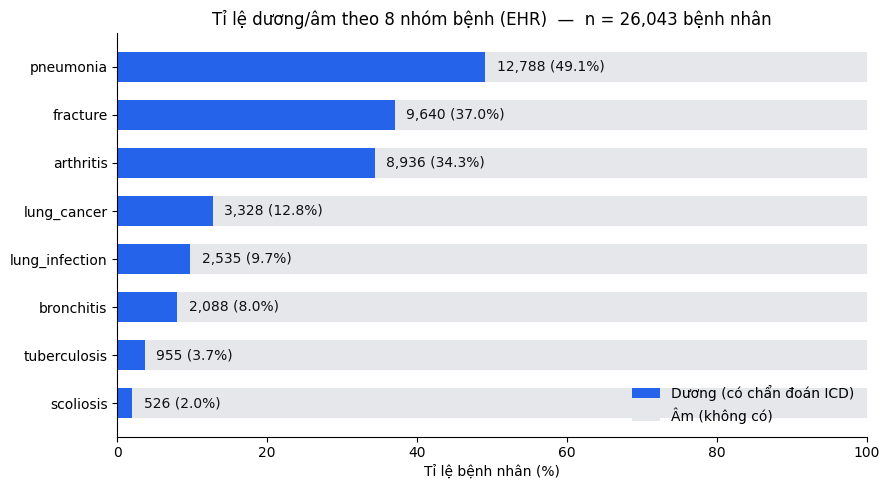

In [8]:
import pandas as pd, numpy as np, os
import matplotlib.pyplot as plt

u = df.drop_duplicates('subject_id')          # mức bệnh nhân
GROUPS = ['pneumonia','bronchitis','tuberculosis','arthritis','fracture','scoliosis','lung_cancer','lung_infection']
N   = len(u)
pos = np.array([int(u['dx_'+g].sum()) for g in GROUPS])
pct = 100*pos/N

order = np.argsort(pct)                        # cao nhất lên trên (barh)
G  = [GROUPS[i] for i in order]; P = pos[order]; PC = pct[order]

POS_C, NEG_C = '#2563eb', '#e5e7eb'            # dương=xanh, âm=xám (an toàn CVD)
fig, ax = plt.subplots(figsize=(9,5))
y = np.arange(len(G))
ax.barh(y, PC,        color=POS_C, height=0.62, label='Dương (có chẩn đoán ICD)')
ax.barh(y, 100-PC, left=PC, color=NEG_C, height=0.62, label='Âm (không có)')
for i,(p,pc) in enumerate(zip(P,PC)):
    ax.text(min(pc+1.5, 88), i, f"{p:,} ({pc:.1f}%)", va='center', ha='left', fontsize=10, color='#111111')
ax.set_yticks(y); ax.set_yticklabels(G)
ax.set_xlim(0,100); ax.set_xlabel('Tỉ lệ bệnh nhân (%)')
ax.set_title(f'Tỉ lệ dương/âm theo 8 nhóm bệnh (EHR)  —  n = {N:,} bệnh nhân')
for s in ['top','right']: ax.spines[s].set_visible(False)
ax.legend(loc='lower right', frameon=False)
plt.tight_layout(); plt.show()
fig.savefig(os.path.join(OUT_DIR,'pos_neg_8diseases.png'), dpi=130, bbox_inches='tight')


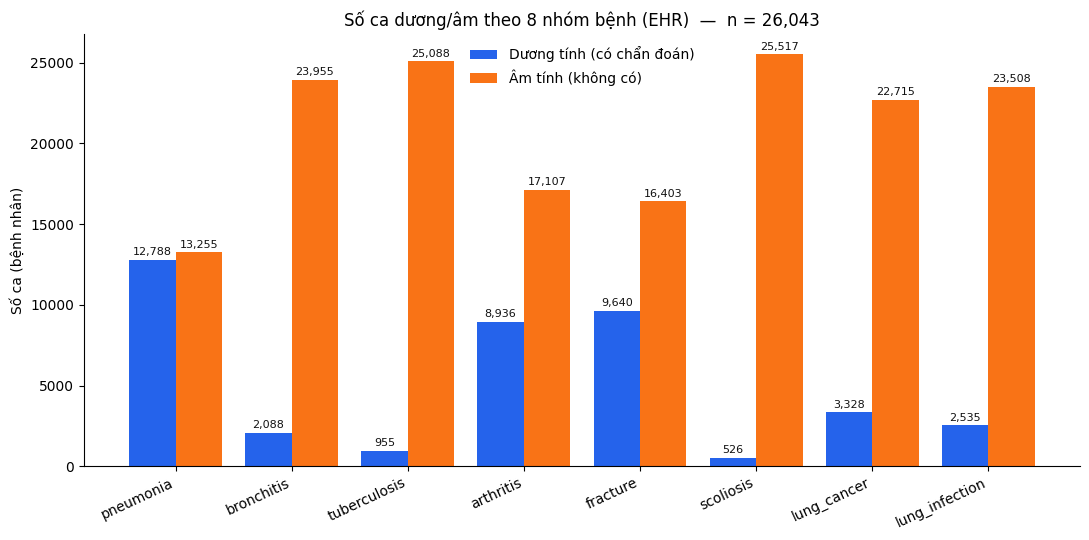

In [ ]:
import pandas as pd, numpy as np, os
import matplotlib.pyplot as plt
df = pd.read_csv(os.path.join(OUT_DIR,'fusion_dataset_hybrid_full.csv'))
u = df.drop_duplicates('subject_id')
GROUPS=['pneumonia','bronchitis','tuberculosis','arthritis','fracture','scoliosis','lung_cancer','lung_infection']
N   = len(u)
pos = np.array([int(u['dx_'+g].sum()) for g in GROUPS])
neg = N - pos

x = np.arange(len(GROUPS)); w = 0.4
POS_C, NEG_C = '#2563eb', '#f97316'          # xanh=dương, cam=âm (cặp an toàn CVD)
fig, ax = plt.subplots(figsize=(11, 5.5))
b1 = ax.bar(x-w/2, pos, w, color=POS_C, label='Dương tính (có chẩn đoán)')
b2 = ax.bar(x+w/2, neg, w, color=NEG_C, label='Âm tính (không có)')
ax.bar_label(b1, fmt='{:,.0f}', padding=2, fontsize=8, color='#111111')
ax.bar_label(b2, fmt='{:,.0f}', padding=2, fontsize=8, color='#111111')
ax.set_xticks(x); ax.set_xticklabels(GROUPS, rotation=25, ha='right')
ax.set_ylabel('Số ca (bệnh nhân)')
ax.set_title(f'Số ca dương/âm theo 8 nhóm bệnh (EHR)  —  n = {N:,}')
for s in ['top','right']: ax.spines[s].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout(); plt.show()
fig.savefig(os.path.join(OUT_DIR,'pos_neg_8diseases_bar.png'), dpi=130, bbox_inches='tight')


ảnh: 231684 | bệnh nhân: 26043
bio numeric: 17 | bị loại: ['ed_intime']


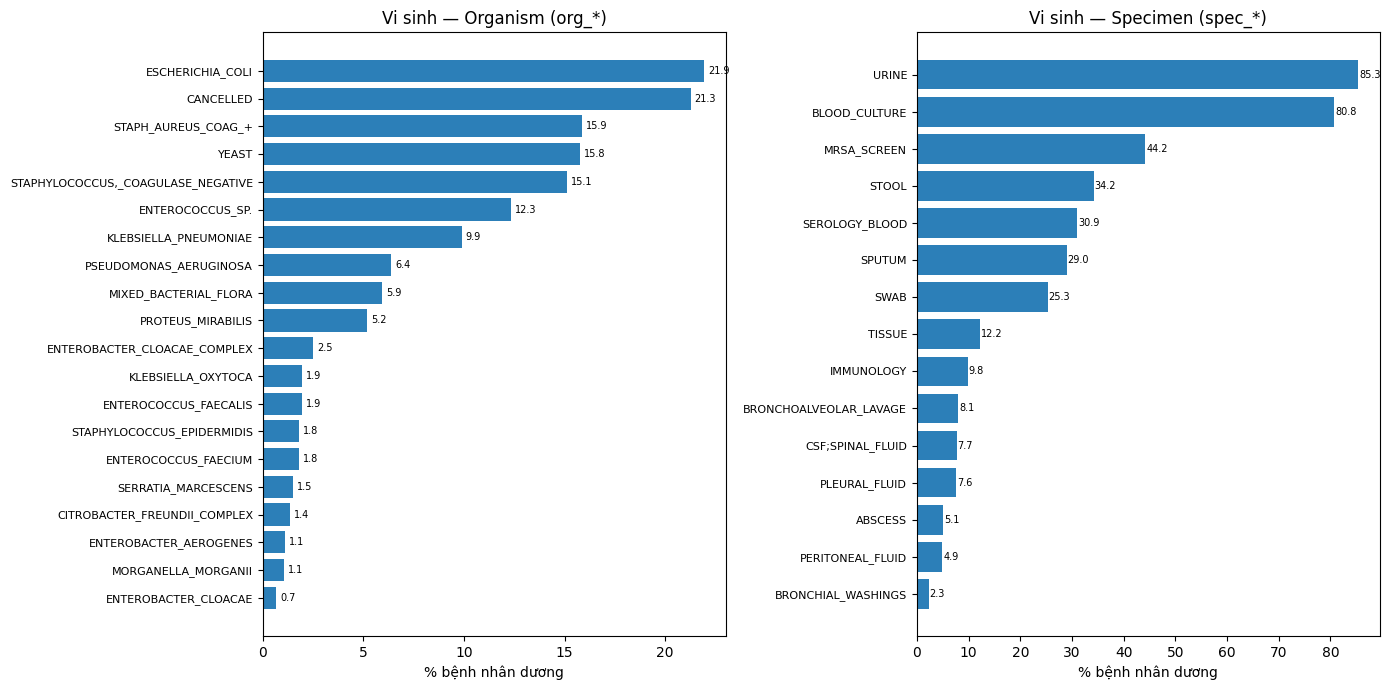

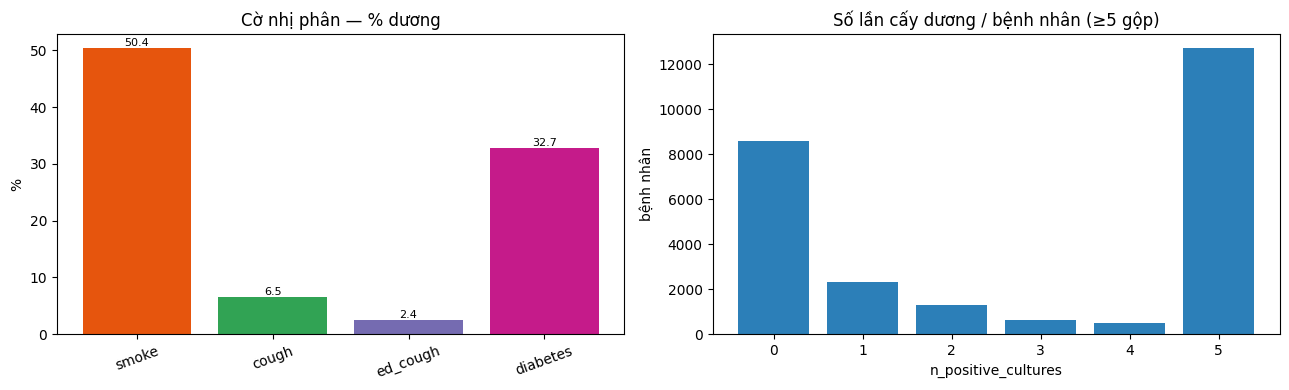

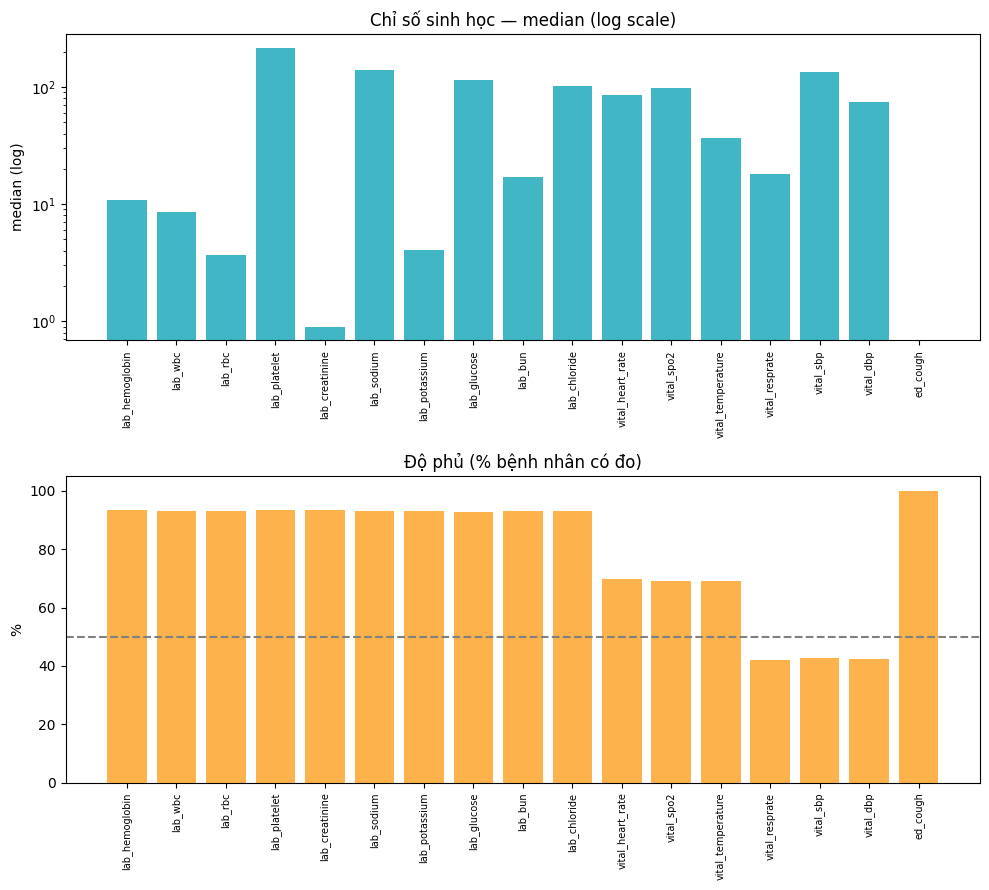

In [12]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, os
# p = os.path.join(OUT_DIR,'fusion_dataset_hybrid_full.csv')

df = pd.read_csv(p, usecols=lambda c: not c.startswith('img_'))
dfp = df.drop_duplicates('subject_id')
print("ảnh:", len(df), "| bệnh nhân:", len(dfp))

org_cols  = [c for c in df.columns if c.startswith('org_')]
spec_cols = [c for c in df.columns if c.startswith('spec_')]
flag_cols = [c for c in ['smoke','cough','ed_cough','diabetes','n_positive_cultures'] if c in df.columns]
cand = [c for c in df.columns if c.startswith('lab_') or c.startswith('vital_') or c.startswith('ed_')]
bio  = [c for c in cand if pd.api.types.is_numeric_dtype(df[c])]   # bỏ ed_intime/datetime
print("bio numeric:", len(bio), "| bị loại:", [c for c in cand if c not in bio])

def barh_prev(cols, title, ax):
    prev = (dfp[cols]>0).mean().sort_values()*100
    ax.barh(range(len(prev)), prev.values, color='#2c7fb8')
    ax.set_yticks(range(len(prev))); ax.set_yticklabels([c.split('_',1)[-1] for c in prev.index], fontsize=8)
    ax.set_title(title); ax.set_xlabel('% bệnh nhân dương')
    for i,v in enumerate(prev.values): ax.text(v+0.2,i,f"{v:.1f}",va='center',fontsize=7)

# 1) VI SINH: organism + specimen
fig,ax = plt.subplots(1,2,figsize=(14,max(4,len(org_cols)*0.35)))
if org_cols:  barh_prev(org_cols,  'Vi sinh — Organism (org_*)',  ax[0])
if spec_cols: barh_prev(spec_cols, 'Vi sinh — Specimen (spec_*)', ax[1])
plt.tight_layout(); plt.show()

# 2) CỜ nhị phân + số lần cấy dương
fig,ax = plt.subplots(1,2,figsize=(13,4))
bin_flags=[c for c in flag_cols if c!='n_positive_cultures']
if bin_flags:
    prev=(dfp[bin_flags]>0).mean()*100
    ax[0].bar(range(len(prev)),prev.values,color=['#e6550d','#31a354','#756bb1','#c51b8a'][:len(prev)])
    ax[0].set_xticks(range(len(prev))); ax[0].set_xticklabels(bin_flags,rotation=20)
    ax[0].set_title('Cờ nhị phân — % dương'); ax[0].set_ylabel('%')
    for i,v in enumerate(prev.values): ax[0].text(i,v,f"{v:.1f}",ha='center',va='bottom',fontsize=8)
if 'n_positive_cultures' in df.columns:
    vc=dfp['n_positive_cultures'].fillna(0).clip(upper=5).astype(int).value_counts().sort_index()
    ax[1].bar(vc.index,vc.values,color='#2c7fb8')
    ax[1].set_title('Số lần cấy dương / bệnh nhân (≥5 gộp)'); ax[1].set_xlabel('n_positive_cultures'); ax[1].set_ylabel('bệnh nhân')
plt.tight_layout(); plt.show()

# 3) CHỈ SỐ SINH HỌC: median (log) + độ phủ
if bio:
    med = dfp[bio].median(); cov = dfp[bio].notna().mean()*100
    fig,ax = plt.subplots(2,1,figsize=(max(10,len(bio)*0.5),9))
    ax[0].bar(range(len(bio)), med.values, color='#41b6c4'); ax[0].set_yscale('log')
    ax[0].set_xticks(range(len(bio))); ax[0].set_xticklabels(bio,rotation=90,fontsize=7)
    ax[0].set_title('Chỉ số sinh học — median (log scale)'); ax[0].set_ylabel('median (log)')
    ax[1].bar(range(len(bio)), cov.values, color='#feb24c')
    ax[1].set_xticks(range(len(bio))); ax[1].set_xticklabels(bio,rotation=90,fontsize=7)
    ax[1].set_title('Độ phủ (% bệnh nhân có đo)'); ax[1].set_ylabel('%'); ax[1].axhline(50,ls='--',c='grey')
    plt.tight_layout(); plt.show()


In [4]:
import pandas as pd, glob, os
DROP = ['chiefcomplaint']

# 1) PARQUET — nguồn chuẩn (giữ đủ ảnh)
for p in glob.glob(os.path.join(OUT_DIR,'fusion_dataset_*.parquet')):
    d = pd.read_parquet(p)
    d = d.drop(columns=[c for c in DROP if c in d.columns], errors='ignore')
    d.to_parquet(p, index=False)
    print("parquet:", os.path.basename(p), "| còn chiefcomplaint?", 'chiefcomplaint' in d.columns,
          "| img:", sum(c.startswith('img_') for c in d.columns))

# 2) CSV — giữ đúng dạng (full nếu vốn có ảnh, light nếu không)
for cp in glob.glob(os.path.join(OUT_DIR,'fusion_dataset_*.csv')):
    had_img = any(c.startswith('img_') for c in pd.read_csv(cp, nrows=0).columns)
    d = pd.read_csv(cp)
    d = d.drop(columns=[c for c in DROP if c in d.columns], errors='ignore')
    if not had_img: d = d[[c for c in d.columns if not c.startswith('img_')]]
    d.to_csv(cp, index=False)
    print("csv:", os.path.basename(cp), "| còn chiefcomplaint?", 'chiefcomplaint' in d.columns, "| img giữ:", had_img)


parquet: fusion_dataset_hybrid.parquet | còn chiefcomplaint? False | img: 768
parquet: fusion_dataset_hybrid_fullmicro.parquet | còn chiefcomplaint? False | img: 768
csv: fusion_dataset_hybrid.csv | còn chiefcomplaint? False | img giữ: False
csv: fusion_dataset_hybrid_full.csv | còn chiefcomplaint? False | img giữ: True
csv: fusion_dataset_hybrid_fullmicro.csv | còn chiefcomplaint? False | img giữ: True


In [5]:
df = pd.read_csv(os.path.join(OUT_DIR,'fusion_dataset_hybrid_full.csv'))
df.shape

(231684, 860)

số BN dương mỗi bệnh: {'pneumonia': 12788, 'bronchitis': 2088, 'tuberculosis': 955, 'arthritis': 8936, 'fracture': 9640, 'scoliosis': 526, 'lung_cancer': 3328, 'lung_infection': 2535}
EHR nhị phân : ['ed_cough', 'smoke', 'cough', 'diabetes']
EHR liên tục : ['age', 'lab_hemoglobin', 'lab_wbc', 'lab_rbc', 'lab_platelet', 'lab_creatinine', 'lab_sodium', 'lab_potassium', 'lab_glucose', 'lab_bun', 'lab_chloride', 'vital_heart_rate', 'vital_spo2', 'vital_temperature', 'vital_resprate', 'vital_sbp', 'vital_dbp', 'n_positive_cultures']
EHR phân loại: ['gender'] | bỏ (free-text nhiều giá trị): []
vi sinh (org+spec): 35


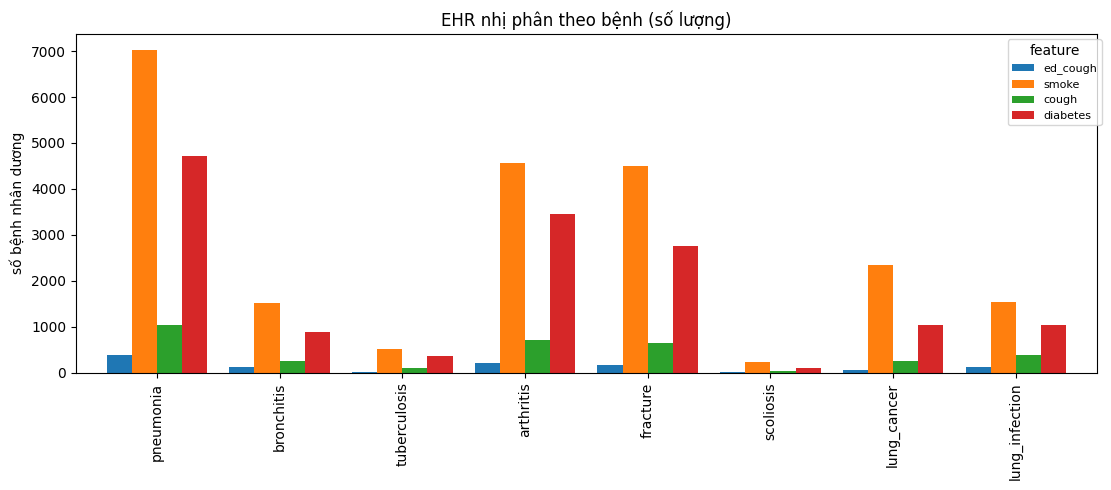

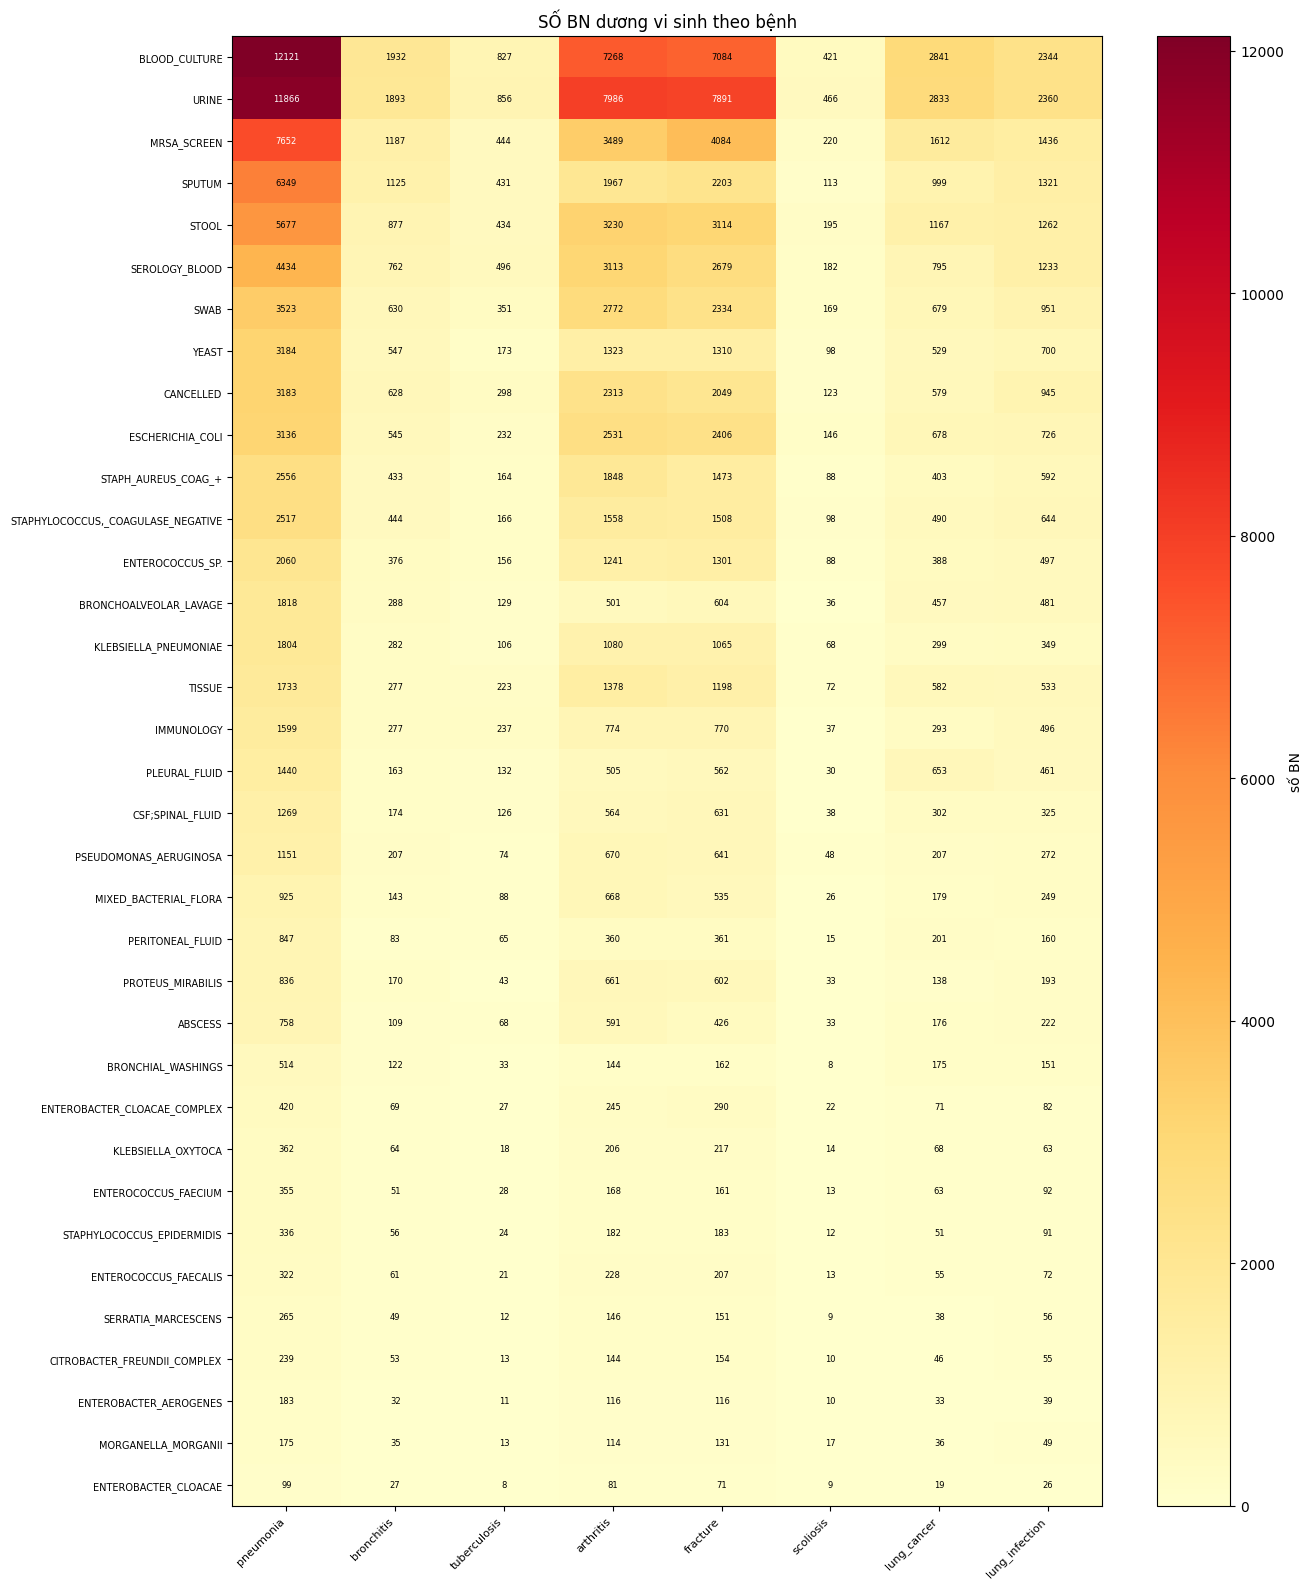

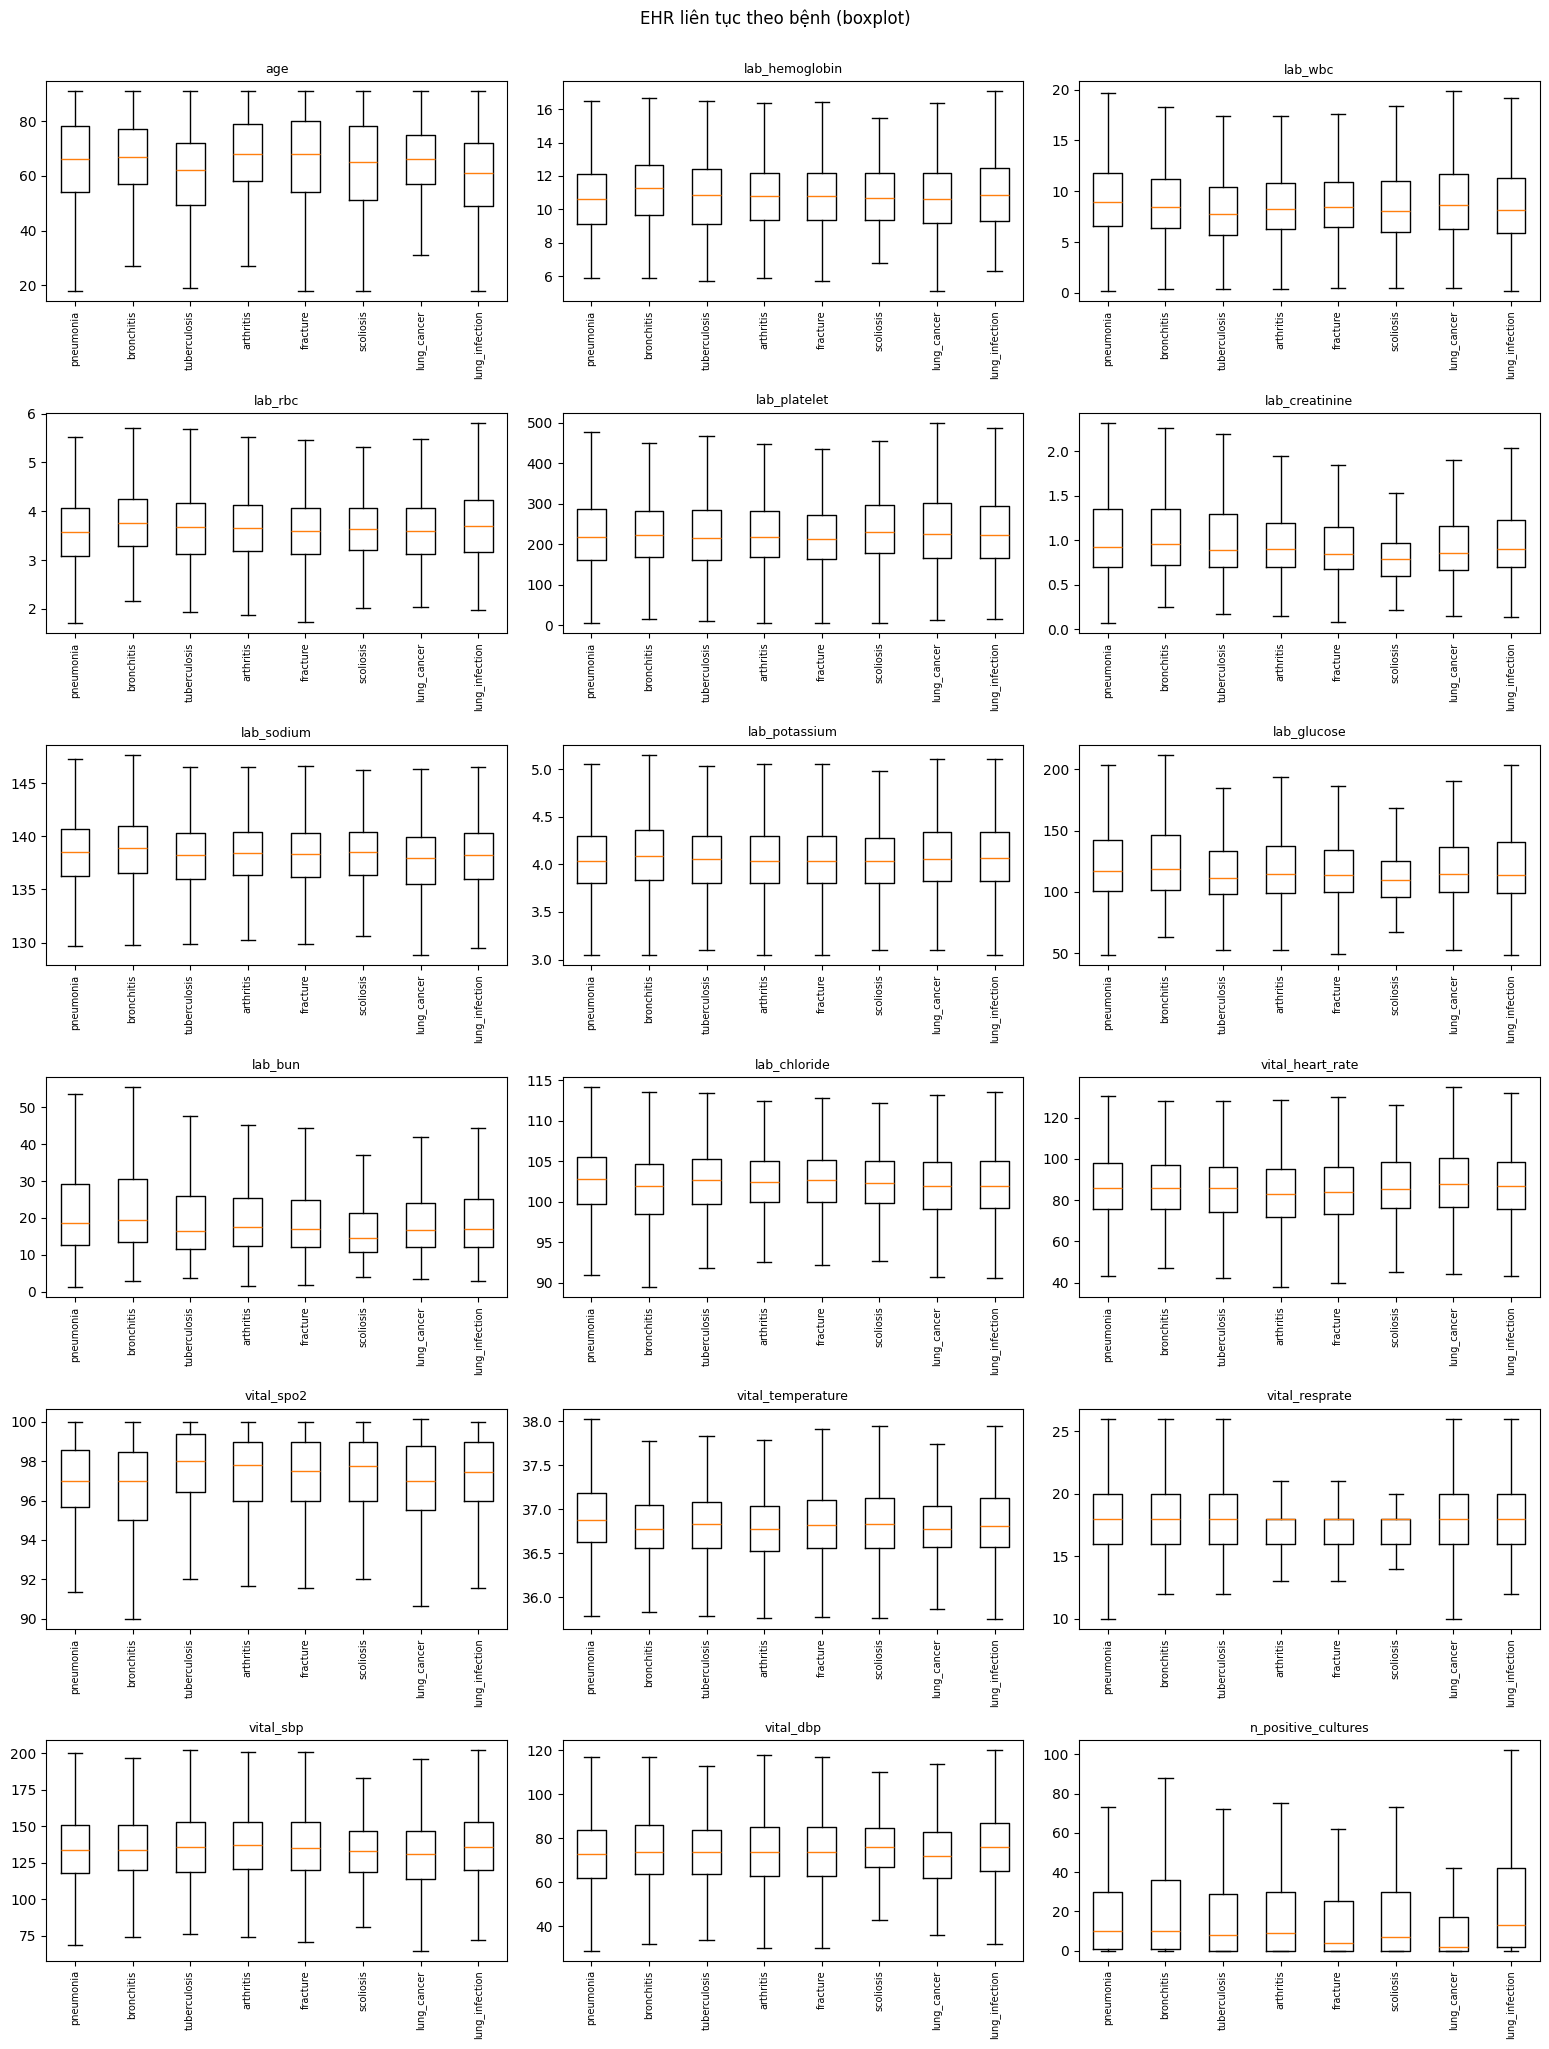

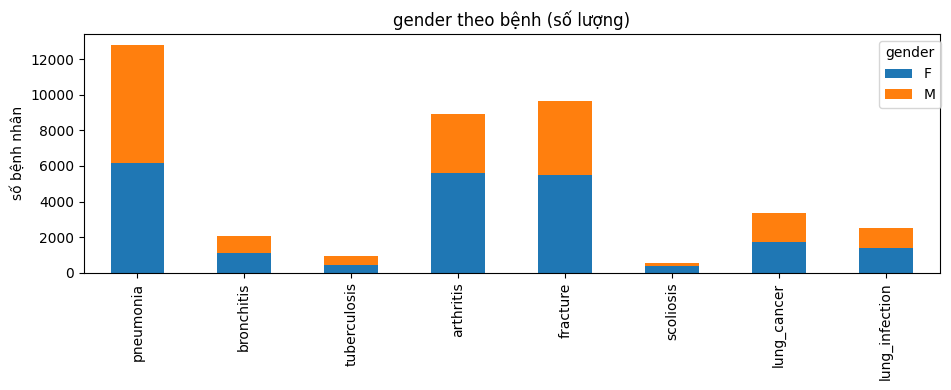

In [6]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, math, os
p = os.path.join(OUT_DIR,'fusion_dataset_hybrid_full.csv')
df = pd.read_csv(p, usecols=lambda c: not c.startswith('img_'))
dfp = df.drop_duplicates('subject_id')
groups = [c[3:] for c in df.columns if c.startswith('dx_')]
subsets = {g: dfp[dfp['dx_'+g]==1] for g in groups}
print("số BN dương mỗi bệnh:", {g: len(s) for g,s in subsets.items()})

# ---- Quét TOÀN BỘ biến EHR (loại id, nhãn, thời gian, ảnh, meta ảnh, free-text) ----
DROP_EXACT = {'dicom_id','subject_id','study_id','hadm_id','stay_id','first_hadm_id',
              'first_admittime','first_icd10_codes','study_dt','admittime','ed_intime',
              'encounter_time','split','view','disease_group','chiefcomplaint'}
ehr   = [c for c in df.columns if not c.startswith(('img_','y_','dx_')) and c not in DROP_EXACT]
micro = [c for c in ehr if c.startswith(('org_','spec_'))]
rest  = [c for c in ehr if c not in micro]
binf  = [c for c in rest if pd.api.types.is_numeric_dtype(df[c]) and df[c].dropna().nunique()<=2]
cont  = [c for c in rest if pd.api.types.is_numeric_dtype(df[c]) and c not in binf]
cat   = [c for c in rest if not pd.api.types.is_numeric_dtype(df[c]) and dfp[c].nunique()<=15]   # bỏ free-text
skip  = [c for c in rest if not pd.api.types.is_numeric_dtype(df[c]) and dfp[c].nunique()>15]
print("EHR nhị phân :", binf)
print("EHR liên tục :", cont)
print("EHR phân loại:", cat, "| bỏ (free-text nhiều giá trị):", skip)
print("vi sinh (org+spec):", len(micro))

# ===== 1) EHR NHỊ PHÂN theo bệnh — SỐ LƯỢNG (grouped bar) =====
if binf:
    mat = pd.DataFrame({g: [subsets[g][c].gt(0).sum() for c in binf] for g in groups}, index=binf)
    ax = mat.T.plot(kind='bar', figsize=(max(11,len(groups)*1.4),5), width=0.82)
    ax.set_ylabel('số bệnh nhân dương'); ax.set_title('EHR nhị phân theo bệnh (số lượng)')
    ax.legend(title='feature', bbox_to_anchor=(1.01,1), fontsize=8); plt.tight_layout(); plt.show()

# ===== 2) VI SINH (org+spec) theo bệnh — SỐ LƯỢNG (heatmap có số) =====
if micro:
    C = pd.DataFrame({g: dfp.loc[dfp['dx_'+g]==1, micro].gt(0).sum() for g in groups})   # index = tên đầy đủ (khớp)
    C = C.loc[C.max(axis=1).sort_values(ascending=False).index]
    fig,ax=plt.subplots(figsize=(1.3*len(groups)+3, 0.4*len(C)+2))
    im=ax.imshow(C.values, aspect='auto', cmap='YlOrRd', vmin=0)
    ax.set_xticks(range(len(groups))); ax.set_xticklabels(groups,rotation=45,ha='right',fontsize=8)
    ax.set_yticks(range(len(C))); ax.set_yticklabels([c.split('_',1)[1] for c in C.index],fontsize=7)
    for i in range(C.shape[0]):
        for j in range(C.shape[1]):
            v=int(C.values[i,j])
            if v>0: ax.text(j,i,v,ha='center',va='center',fontsize=6,
                            color='white' if v>C.values.max()*0.6 else 'black')
    ax.set_title('SỐ BN dương vi sinh theo bệnh'); fig.colorbar(im,label='số BN'); plt.tight_layout(); plt.show()

# ===== 3) EHR LIÊN TỤC (labs/vitals/age) theo bệnh — BOXPLOT =====
if cont:
    ncol=3; nrow=math.ceil(len(cont)/ncol)
    fig,axes=plt.subplots(nrow,ncol,figsize=(5.2*ncol,3.4*nrow)); axes=np.array(axes).flatten()
    for i,f in enumerate(cont):
        data=[subsets[g][f].dropna().values for g in groups]
        axes[i].boxplot(data, showfliers=False)        # ẩn outlier để nhìn được hộp; WBC… lệch mạnh
        axes[i].set_xticks(range(1,len(groups)+1)); axes[i].set_xticklabels(groups,rotation=90,fontsize=7)
        axes[i].set_title(f,fontsize=9)
    for j in range(len(cont),len(axes)): axes[j].axis('off')
    fig.suptitle('EHR liên tục theo bệnh (boxplot)', y=1.002); plt.tight_layout(); plt.show()

# ===== 4) EHR PHÂN LOẠI (gender…) theo bệnh — SỐ LƯỢNG (stacked bar) =====
for c in cat:
    ct = pd.DataFrame({g: subsets[g][c].value_counts() for g in groups}).T.fillna(0)
    ax = ct.plot(kind='bar', stacked=True, figsize=(max(9,len(groups)*1.2),4))
    ax.set_ylabel('số bệnh nhân'); ax.set_title(f'{c} theo bệnh (số lượng)')
    ax.legend(title=c, bbox_to_anchor=(1.01,1)); plt.tight_layout(); plt.show()


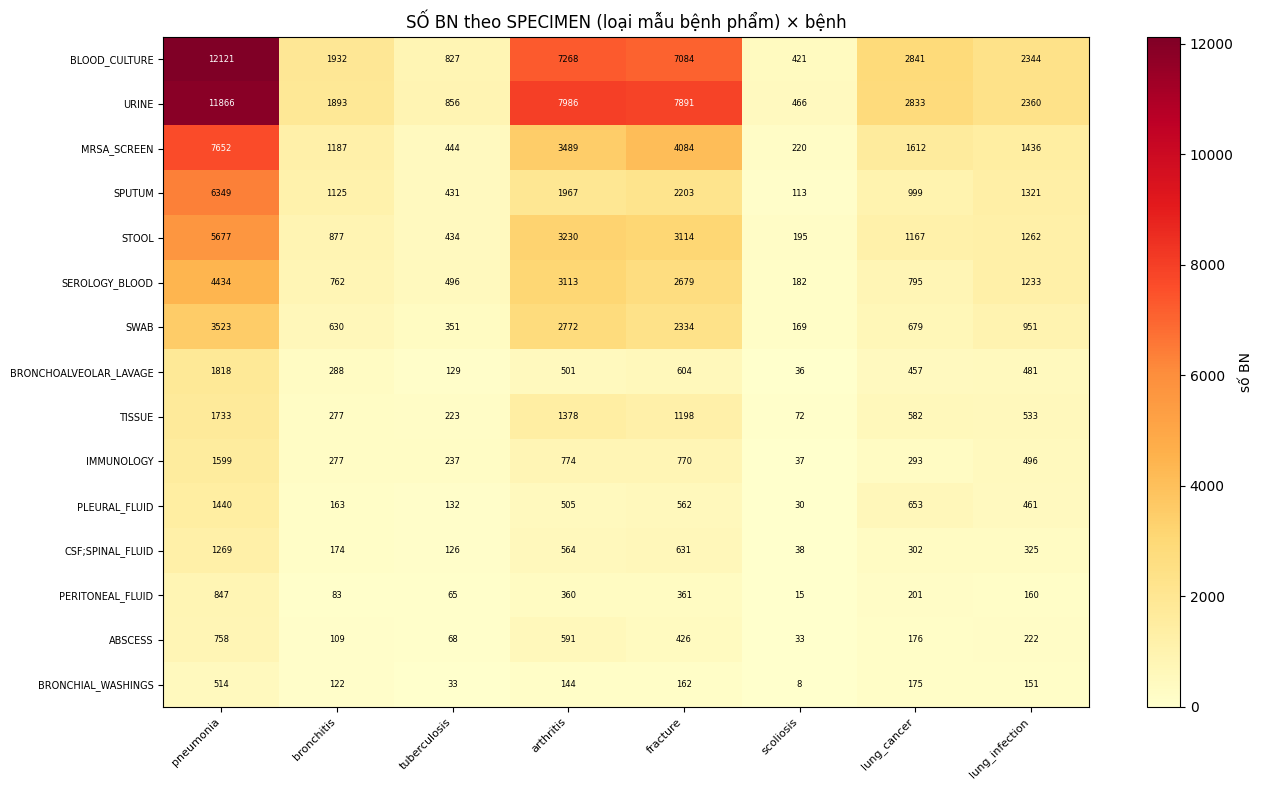

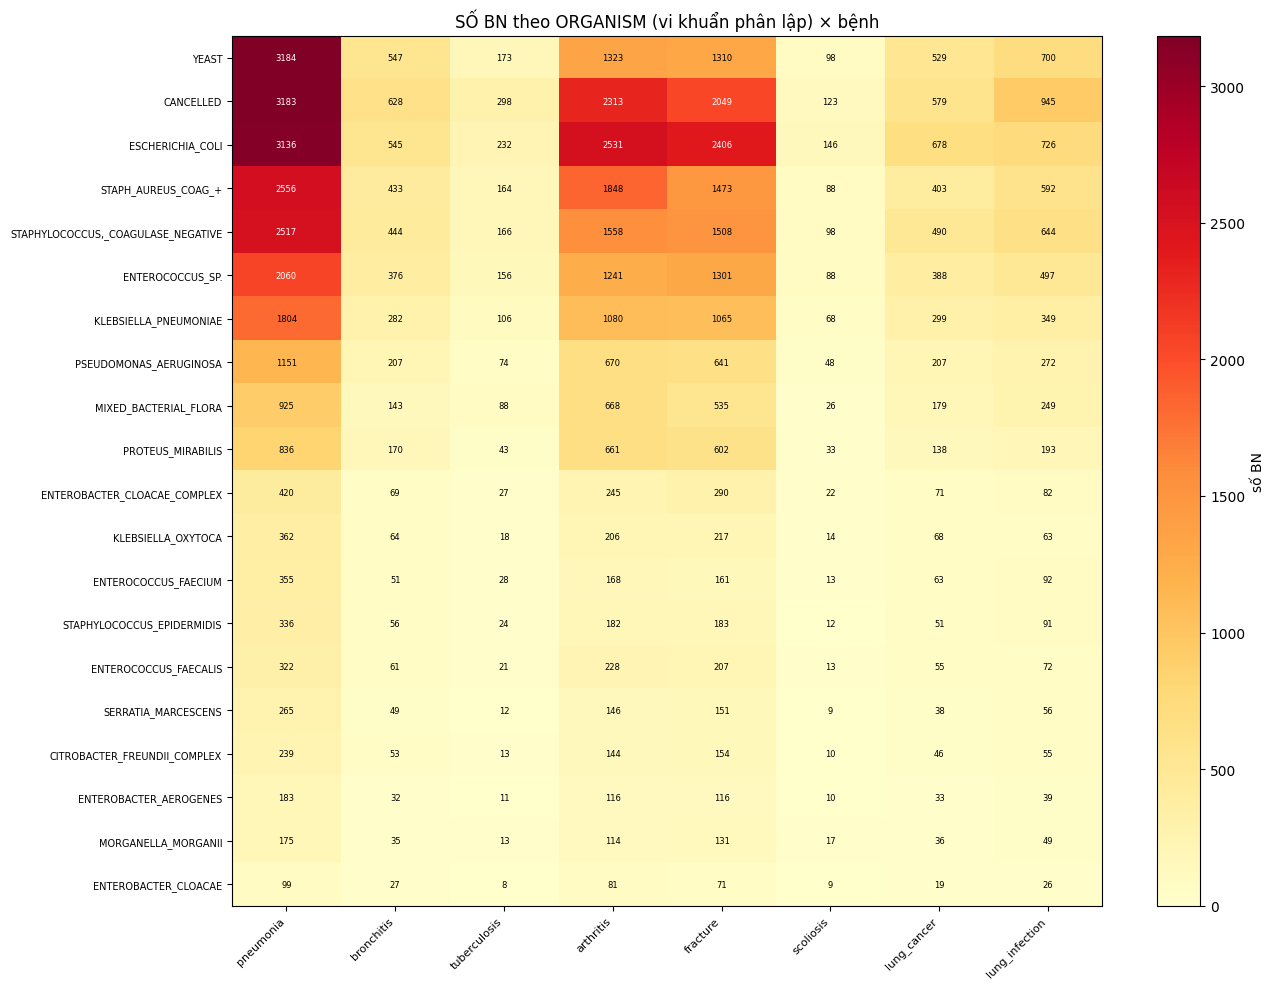

In [7]:
def heat_micro(cols, title):
    if not cols: return
    C = pd.DataFrame({g: dfp.loc[dfp['dx_'+g]==1, cols].gt(0).sum() for g in groups})
    C = C.loc[C.max(axis=1).sort_values(ascending=False).index]
    fig,ax=plt.subplots(figsize=(1.3*len(groups)+3, 0.4*len(C)+2))
    im=ax.imshow(C.values, aspect='auto', cmap='YlOrRd', vmin=0)
    ax.set_xticks(range(len(groups))); ax.set_xticklabels(groups,rotation=45,ha='right',fontsize=8)
    ax.set_yticks(range(len(C))); ax.set_yticklabels([c.split('_',1)[1] for c in C.index],fontsize=7)
    for i in range(C.shape[0]):
        for j in range(C.shape[1]):
            v=int(C.values[i,j])
            if v>0: ax.text(j,i,v,ha='center',va='center',fontsize=6,
                            color='white' if v>C.values.max()*0.6 else 'black')
    ax.set_title(title); fig.colorbar(im,label='số BN'); plt.tight_layout(); plt.show()

spec_cols = [c for c in df.columns if c.startswith('spec_')]
org_cols  = [c for c in df.columns if c.startswith('org_')]
heat_micro(spec_cols, 'SỐ BN theo SPECIMEN (loại mẫu bệnh phẩm) × bệnh')
heat_micro(org_cols,  'SỐ BN theo ORGANISM (vi khuẩn phân lập) × bệnh')


biến liên tục dùng: ['age', 'lab_hemoglobin', 'lab_wbc', 'lab_rbc', 'lab_platelet', 'lab_creatinine', 'lab_sodium', 'lab_potassium', 'lab_glucose', 'lab_bun', 'lab_chloride', 'vital_heart_rate', 'vital_spo2', 'vital_temperature', 'vital_resprate', 'vital_sbp', 'vital_dbp', 'ed_cough']
PCA variance ratio: [0.138 0.103]


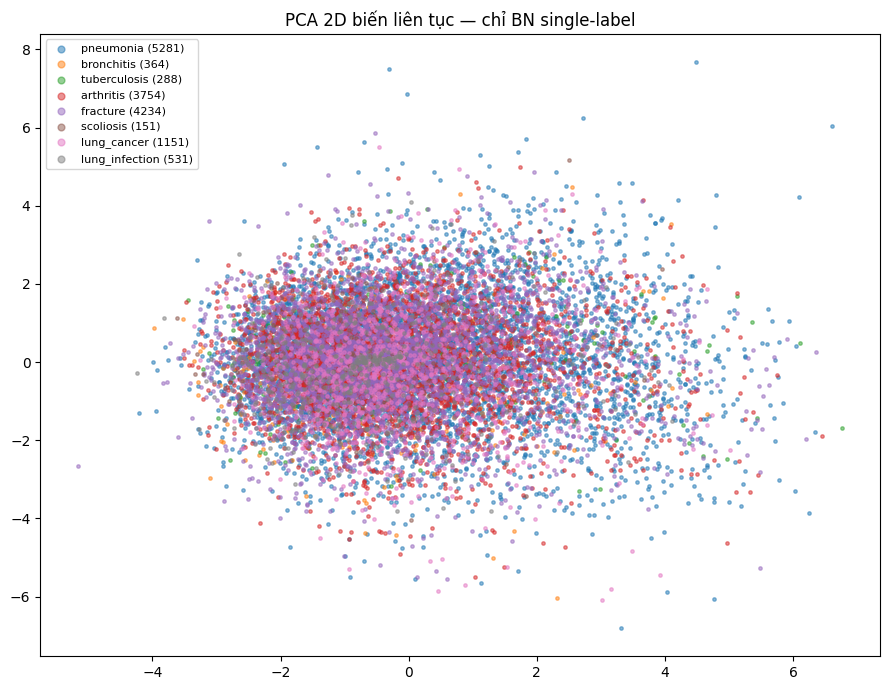

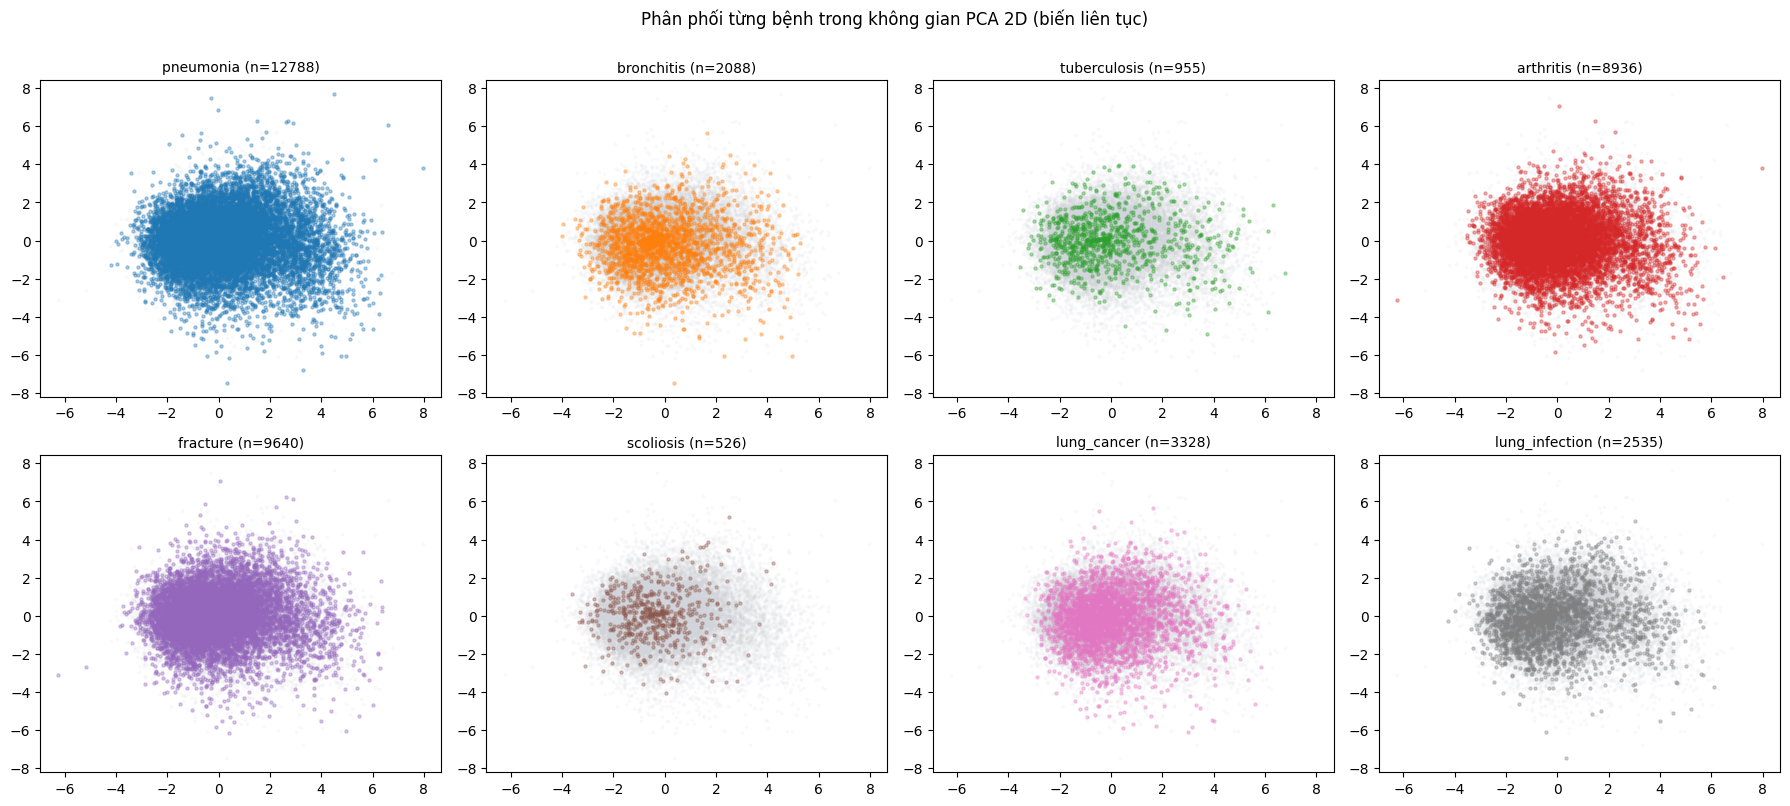

In [4]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, os
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA

if 'dfp' not in globals():
    p = os.path.join(OUT_DIR,'fusion_dataset_hybrid_full.csv')
    df = pd.read_csv(p, usecols=lambda c: not c.startswith('img_'))
    dfp = df.drop_duplicates('subject_id')
groups = [c[3:] for c in dfp.columns if c.startswith('dx_')]

# --- biến liên tục ---
cont = ['age'] + [c for c in dfp.columns if c.startswith(('lab_','vital_','ed_'))]
cont = [c for c in dict.fromkeys(cont) if c in dfp.columns and pd.api.types.is_numeric_dtype(dfp[c])]
print("biến liên tục dùng:", cont)

X = dfp[cont].apply(pd.to_numeric, errors='coerce')
X.loc[:, [c for c in cont if c.startswith('lab_')]] = np.log1p(X[[c for c in cont if c.startswith('lab_')]].clip(lower=0))  # labs lệch -> log
Ximp = SimpleImputer(strategy='median').fit_transform(X)
Xs   = StandardScaler().fit_transform(Ximp)
emb  = PCA(n_components=2, random_state=0).fit_transform(Xs)
print("PCA variance ratio:", PCA(2).fit(Xs).explained_variance_ratio_.round(3))

# ===== A) scatter gộp — bệnh nhân single-label, 8 màu =====
dxmat  = dfp[['dx_'+g for g in groups]].values.astype(int)
single = dxmat.sum(1)==1
lab    = np.array(groups)[dxmat[single].argmax(1)]
cmap   = plt.get_cmap('tab10')
plt.figure(figsize=(9,7))
for i,g in enumerate(groups):
    m = lab==g
    plt.scatter(emb[single][m,0], emb[single][m,1], s=6, alpha=.5, color=cmap(i), label=f'{g} ({m.sum()})')
plt.legend(fontsize=8, markerscale=2); plt.title('PCA 2D biến liên tục — chỉ BN single-label'); plt.tight_layout(); plt.show()

# ===== B) 8 ô one-vs-rest (gồm cả đa nhãn) =====
fig,axes=plt.subplots(2,4,figsize=(18,8)); axes=axes.reshape(-1)
for k,g in enumerate(groups):
    pos = dfp['dx_'+g].values==1
    axes[k].scatter(emb[~pos,0],emb[~pos,1],s=3,alpha=.08,color='#d1d5db')
    axes[k].scatter(emb[pos,0], emb[pos,1], s=5,alpha=.35,color=cmap(k))
    axes[k].set_title(f'{g} (n={int(pos.sum())})',fontsize=10)
fig.suptitle('Phân phối từng bệnh trong không gian PCA 2D (biến liên tục)', y=1.002)
plt.tight_layout(); plt.show()


In [21]:
from google.cloud import bigquery
import pandas as pd, os
client = bigquery.Client(project=BILLING_PROJECT)

# 1) cờ tiểu đường / bệnh nhân — ICD-10 E08–E13 + ICD-9 250.x
diab = client.query(f"""
WITH cohort AS (SELECT DISTINCT subject_id FROM ({TARGET_ADM}))
SELECT d.subject_id,
  MAX(CASE WHEN (d.icd_version=10 AND (d.icd_code LIKE 'E08%' OR d.icd_code LIKE 'E09%'
                    OR d.icd_code LIKE 'E10%' OR d.icd_code LIKE 'E11%' OR d.icd_code LIKE 'E13%'))
             OR (d.icd_version=9  AND d.icd_code LIKE '250%') THEN 1 ELSE 0 END) AS diabetes
FROM `{H}.diagnoses_icd` d JOIN cohort c USING (subject_id)
GROUP BY d.subject_id
""").to_dataframe()
print(f"Tiểu đường: {int(diab.diabetes.sum())} / {len(diab)} ({100*diab.diabetes.mean():.1f}%)")

# 2) thêm cột 'diabetes' vào file, khớp subject_id (ai không có -> 0)
def add_diabetes(path):
    if not os.path.exists(path): print("  bỏ qua (chưa có):", os.path.basename(path)); return
    df = pd.read_parquet(path) if path.endswith('.parquet') else pd.read_csv(path)
    df = df.drop(columns=['diabetes'], errors='ignore').merge(diab, on='subject_id', how='left')
    df['diabetes'] = df['diabetes'].fillna(0).astype('int8')
    (df.to_parquet if path.endswith('.parquet') else lambda p,**k: df.to_csv(p,**k))(path, index=False)
    print("  +diabetes:", os.path.basename(path), df.shape)

# chọn file cần thêm
add_diabetes(os.path.join(OUT_DIR,'fusion_dataset_hybrid.parquet'))          # nhanh
add_diabetes(os.path.join(OUT_DIR,'fusion_dataset_hybrid.csv'))              # light, nhanh
add_diabetes(os.path.join(OUT_DIR,'fusion_dataset_hybrid_full.csv'))
add_diabetes(os.path.join(OUT_DIR,'fusion_dataset_hybrid_fullmicro.parquet'))   
add_diabetes(os.path.join(OUT_DIR,'fusion_dataset_hybrid_fullmicro.csv'))          # ~1.5GB, CHẬM
# add_diabetes(os.path.join(OUT_DIR,'manifest_cohort.parquet'))             # nếu muốn fusion sau này tự có


Tiểu đường: 18388 / 70326 (26.1%)
  +diabetes: fusion_dataset_hybrid.parquet (210989, 861)
  +diabetes: fusion_dataset_hybrid.csv (210989, 861)
  +diabetes: fusion_dataset_hybrid_full.csv (210989, 861)
  +diabetes: fusion_dataset_hybrid_fullmicro.parquet (210989, 1528)


: 

: 

: 

In [6]:
import pandas as pd, os, glob
DROP = ['admission_type','insurance','marital_status','race']

def drop_admin(path):
    if not os.path.exists(path): return
    df = pd.read_parquet(path) if path.endswith('.parquet') else pd.read_csv(path)
    have = [c for c in DROP if c in df.columns]
    if not have: print("  (không có cột cần xoá):", os.path.basename(path)); return
    df = df.drop(columns=have)
    if path.endswith('.parquet'): df.to_parquet(path, index=False)
    else: df.to_csv(path, index=False)
    print("  xoá", have, "->", os.path.basename(path), df.shape, "| img:", len([c for c in df.columns if c.startswith('img_')]))

# tất cả parquet
for p in glob.glob(os.path.join(OUT_DIR,'fusion_dataset_*.parquet')):
    drop_admin(p)
# csv (light nhanh; full ~1.5GB chậm)
drop_admin(os.path.join(OUT_DIR,'fusion_dataset_hybrid.csv'))
drop_admin(os.path.join(OUT_DIR,'fusion_dataset_hybrid_full.csv'))
drop_admin(os.path.join(OUT_DIR,'fusion_dataset_hybrid_fullmicro.csv'))

  xoá ['admission_type', 'insurance', 'marital_status', 'race'] -> fusion_dataset_hybrid.parquet (210989, 857) | img: 768
  xoá ['admission_type', 'insurance', 'marital_status', 'race'] -> fusion_dataset_hybrid_fullmicro.parquet (210989, 1524) | img: 768
  xoá ['admission_type', 'insurance', 'marital_status', 'race'] -> fusion_dataset_hybrid.csv (210989, 857) | img: 768
  xoá ['admission_type', 'insurance', 'marital_status', 'race'] -> fusion_dataset_hybrid_full.csv (210989, 857) | img: 768


In [10]:
drop_admin(os.path.join(OUT_DIR,'fusion_dataset_hybrid_fullmicro.csv'))

: 

: 

: 

In [ ]:
df = pd.read_csv(os.path.join(OUT_DIR,'fusion_dataset_hybrid_full.csv'))
df.shape

TypeError: 'tuple' object is not callable

In [ ]:
df = pd.read_csv(os.path.join(OUT_DIR,'fusion_dataset_hybrid_fullmicro.csv'))
df.shape